# BEM Section 1: Autumn Project Submission
**Group Number:** 07  
**Members:**  
* Aditya Vinay Kumar (Roll Number: 26MT10002)  
* Keenjal Chakraborty (Roll Number: 26MT10052)  
* Himendra Saikrishna (Roll Number: 26MT10054)    
* Pratik Kumar Sahoo (Roll Number: 26MT10067)
* Pravam Kumar Beura (Roll Number: 26MT10068)

## 1. Problem Statement & System Overview
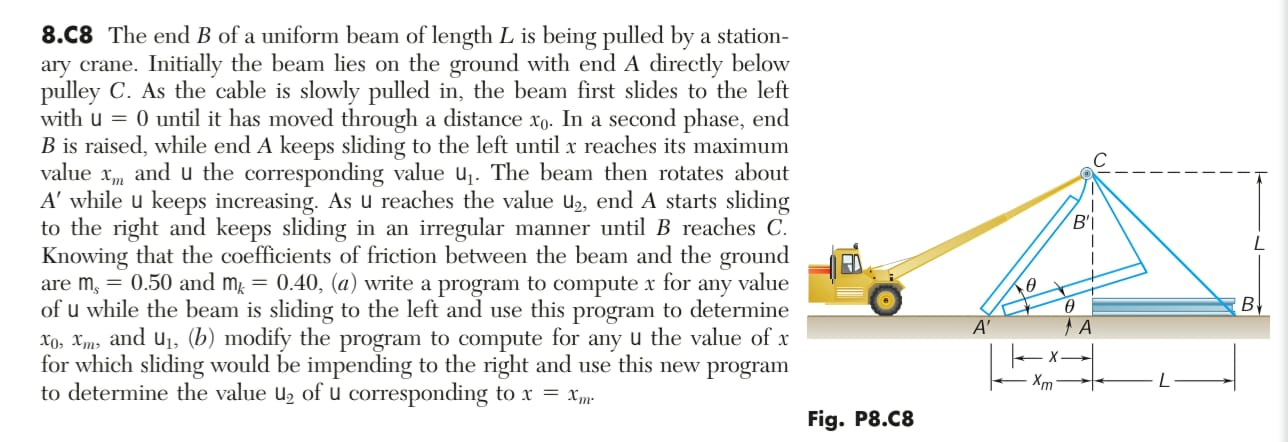
**NOTE**: Instead of using $m_k$ and $m_s$, $\mu_k$ and $\mu_s$ were used. Also, instead of $u$, $u1$ and $u2$, $\theta$, $\theta_1$ and $\theta_2$ are used respectively. This has been done to convey the meanings behind the symbols more clearly. Also, keep in mind the subscripts written next to the commonly used notations or symbols.

**UPDATED NOTATION DESCRIPTION**:
|Notation or Symbol|Description|
|:---:|:---:|
|$W$|Weight of the beam|
|$N$|Normal Reaction at a particular point|
|$L$|Length of the Beam|
|$D$|Length of the cable at any instant|
|$f$|Friction at a particular point|
|$T$|Tension in the cable|
|$F$|Force or any of its components|
|$\phi$|Angle made by the cable with the horizontal|
|$\theta$|Angle made by the beam with the horizontal|
|$\mu$|Coefficient of friction|

This project analyzes the multi-phase equilibrium and motion of a uniform rigid beam of length $L$ and weight $W$. The beam is manipulated by a connected cable. The behavior is divided into three distinct phases based on the lifting condition and friction dynamics:

1. **Phase 1 (Flat Beam Sliding Left):** The beam rests on a frictional surface and is lifted from one end ($B$) using a cable attached at an angle $\phi$. We determine the kinetic friction coefficient $\mu_k$ based on the geometric configurations at the instant of lifting.
2. **Phase 2 (Inclined Beam Sliding Left):** After end $B$ lifts off, the inclined beam persists in motion. We evaluate the relationship between the cable tension $T$, the angle $\theta$, and the horizontal shift $x$ to locate the critical maximum position $x_m$.
3. **Phase 3 (Pure Rotation About $A$ Till Impending Slip):** As rotation continues, end $A$ reaches a state of impending slip to the right. We compute the second critical angle $\theta_2$ using the maximum position $x_m$ and the static coefficient of friction $\mu_s$.

---

## Phase 1: Flat Beam Sliding Left

Here is the free body diagram.
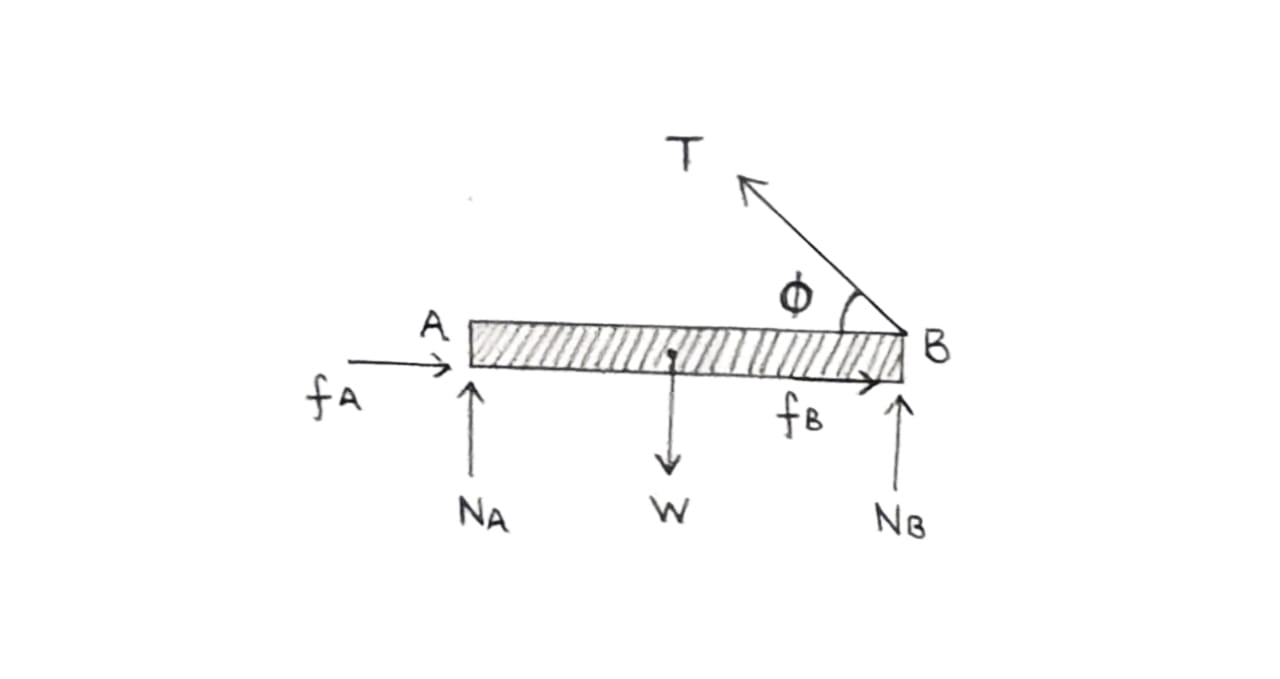
### Governing Equations
From the free-body diagram at the instant of lifting ($N_B = 0$):
* $\Sigma F_x = 0 \implies f_A + f_B - T\cos\phi = 0$
* $\Sigma F_y = 0 \implies N_A + N_B + T\sin\phi - W = 0$
* $\Sigma M_A = 0 \implies W\left(\frac{L}{2}\right) - N_B(L) - T\sin\phi(L) = 0$
Since the beam is in motion, friction is a kinetic phenomena; $f_A=\mu_k N_A$ and $f_B=\mu_k N_B$. 

From these conditions, at the transition point where lifting begins:
$$\tan\phi = \frac{1}{\mu_k}$$
Given that $$\tan\phi = \frac{L}{L-x}$$
So, by comparison: $$\frac{1}{\mu_k} = \frac{L}{L-x}$$
Substituting the value of $\mu_k$ as 0.4, the value of $x_0$ in terms of $L$ is: $$x_0 = 0.6L$$ 
Additionally,
$$\tan\phi = \frac{1}{1 - 0.6} = \frac{1}{0.4} = 2.5$$

$$\phi_{0} = 68.1986^\circ$$

In [491]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

# Phase 1: Calculating Friction Coefficient and Angle

# Geometric parameters given in the problem
x_ratio = 0.6 # x = 0.6 * L

# Calculating tan phi
tan_phi = 1 / (1 - x_ratio)
phi_rad = np.arctan(tan_phi)
phi_deg = np.degrees(phi_rad)

# Since tan phi = 1 / mu_k at lifting transition
mu_k = 1 / tan_phi

print("Phase 1 Results ")
print(f"Calculated tan(phi): {tan_phi:.4f}")
print(f"Lifting Angle phi: {phi_deg:.4f} degrees")
print(f"Kinetic Friction Coefficient (mu_k): {mu_k:.4f}")

Phase 1 Results 
Calculated tan(phi): 2.5000
Lifting Angle phi: 68.1986 degrees
Kinetic Friction Coefficient (mu_k): 0.4000


---

## Phase 2: System Optimization (Finding Maximum $x_m$)

### Analytical Formulation
B is lifted and beam is inclined at angle $\theta$.
Setting up the system geometry, 

$C(0, L)$  
$A(-x, 0)$  
$B(-x + L\cos\theta, L\sin\theta)$  

Here is the diagram showing the geometry of the system.
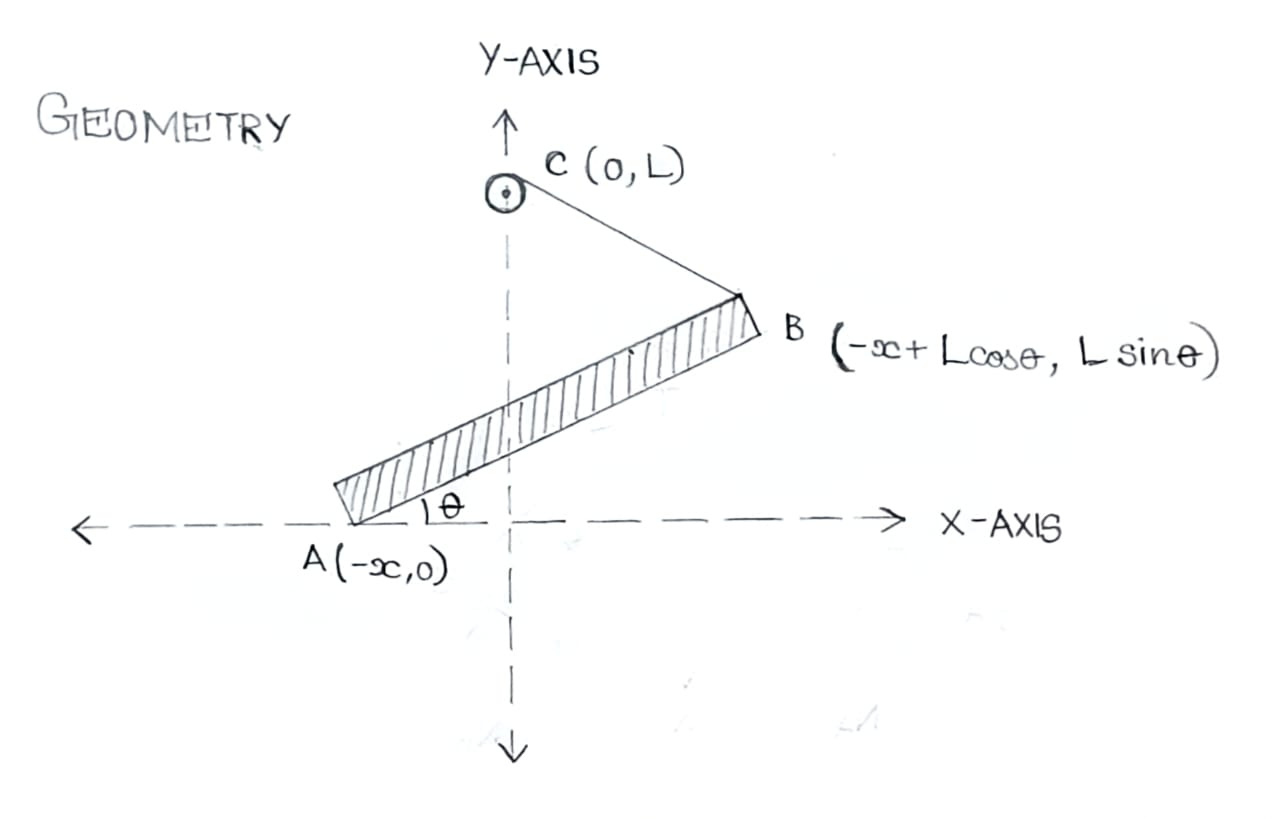

$$\vec{r}_{AB} = L\cos\theta\,\hat{i} + L\sin\theta\,\hat{j}$$

$\therefore$ Unit Vector along cable BC:
$$\vec{r}_{BC} = \frac{(x - L\cos\theta)\hat{i} + L(1 - \sin\theta)\hat{j}}{D}$$
$$D = \sqrt{(x - L\cos\theta)^2 + L^2(1 - \sin\theta)^2}$$

---
Here is the free body diagram for the second phase.
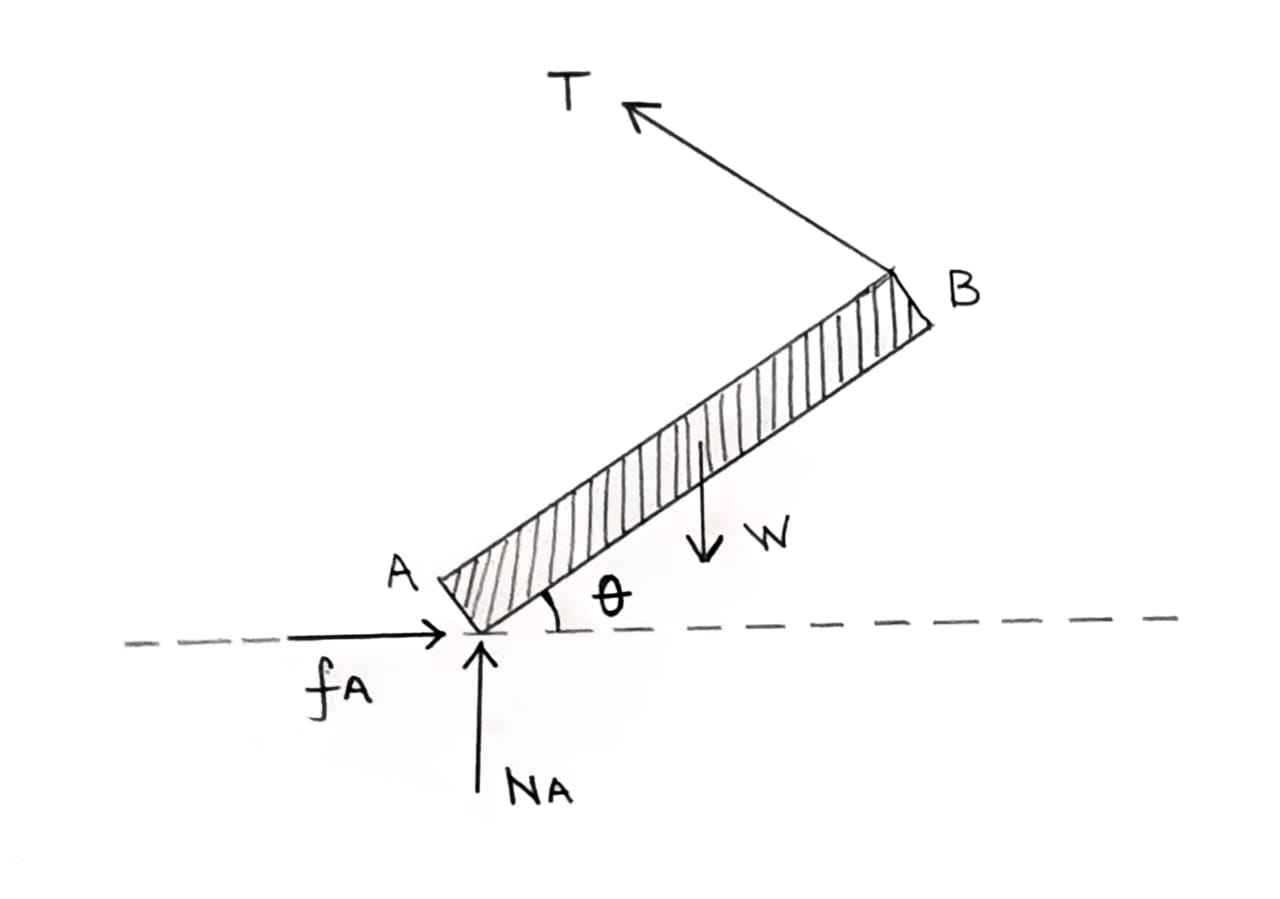

#### Tension Vector:
$$\vec{T} = \frac{T}{D}(x - L\cos\theta)\hat{i} + \frac{T}{D}(L(1 - \sin\theta))\hat{j}$$
$$\therefore T_x = \frac{T}{D}(x - L\cos\theta) \quad T_y = \frac{T}{D}(L(1 - \sin\theta))$$

#### Moment due to Tension about A:
$$\vec{M} = \vec{r} \times \vec{T}$$
$$\vec{M} = (L\cos\theta\,\hat{i} + L\sin\theta\,\hat{j}) \times \left( \frac{T}{D}(x - L\cos\theta)\hat{i} + \frac{T}{D}(L(1 - \sin\theta))\hat{j} \right)$$
$$= \left[ \frac{T}{D} L^2(\cos\theta - \sin\theta\cos\theta) - \frac{T}{D} L x\sin\theta + \frac{T}{D} L^2\sin\theta\cos\theta \right] \hat{k}$$
$$= \frac{T}{D} \left( L^2\cos\theta - L^2\sin\theta\cos\theta - L x\sin\theta + L^2\sin\theta\cos\theta \right)$$
$$= \frac{TL}{D}(L\cos\theta - x\sin\theta) \quad \text{(counter clockwise)}$$

#### Moment due to Weight:
$$\vec{M}_w = W\left(\frac{L}{2}\right)\cos\theta \quad \text{(clockwise)}$$

Since B is lifted both $N$ & $f$ act at $A$ so they don't contribute any moment:
$$\sum M_A = 0 \implies \frac{TL}{D}(L\cos\theta - x\sin\theta) = \frac{W L}{2}\cos\theta$$
$$\implies \frac{T}{D} = \frac{W\cos\theta}{2(L\cos\theta - x\sin\theta)}$$

#### Derivation Steps

In the Y - direction,
$$\Sigma F_y = 0$$
$$N_A + T_y - W = 0$$
$$\quad N_A = W - \frac{T}{D} L(1 - \sin\theta)$$

In the X - direction,
$$\Sigma F_x = 0$$
$$T_x + f_A = 0 \quad \rightarrow \text{points right and opposes motion}$$
$$f_A = -T_x$$
$$ \quad f_A = \frac{T}{D} (L\cos\theta - x)$$
Now,
$$f_A = \mu_k N_A$$
$$\quad \frac{T}{D} (L\cos\theta - x) = \mu_k \left( W - \frac{T}{D} L(1 - \sin\theta) \right)$$

$$\text{Let } \Gamma = L\cos\theta - x\sin\theta$$

$$\frac{T}{D} = \frac{W\cos\theta}{2\Gamma}$$
$$\frac{W\cos\theta}{2\Gamma} (L\cos\theta - x) = \mu_k \left( W - \frac{W\cos\theta}{2\Gamma} L(1 - \sin\theta) \right)$$
$$L\cos^2\theta - x\cos\theta = \mu_k 2\Gamma - L\cos\theta + L\sin\theta\cos\theta$$
$$\mathbf{x = \frac{L\cos\theta (\cos\theta - \mu_k (1 + \sin\theta))}{(\cos\theta - 2\mu_k \sin\theta)}}$$

Let us see a visual representation of the same using a plot between $\frac{x}{L}$ and $\theta$ in degrees.

Note: The denominator tends to zero at approximately $51.3^\circ$. Hence there is an asymptote in the plot. So plot is generated from 0 to 50 degrees to stay in the safe zone.
This was found out after getting division by zero error one time and a logical error the next time while plotting the x axis from 0 to 60 degrees.

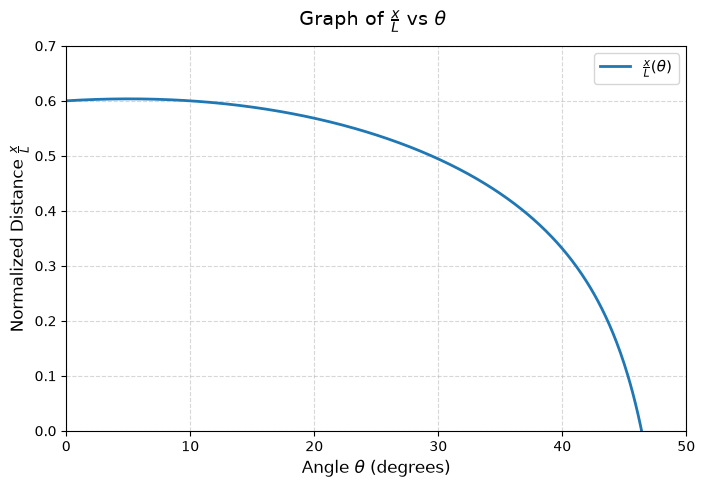

In [492]:
mu_k = 0.4

# Generate angles from 0 to 50 degrees to safely avoid the asymptote at ~51.3°
theta_deg = np.linspace(0, 50, 500)
theta_rad = np.radians(theta_deg)

# Derived equation 
numerator = np.cos(theta_rad) * (np.cos(theta_rad) - mu_k * (1 + np.sin(theta_rad)))
denominator = np.cos(theta_rad) - 2 * mu_k * np.sin(theta_rad)
ratio = numerator / denominator

# Make the plot
plt.figure(figsize=(8, 5))
plt.plot(theta_deg, ratio, color='tab:blue', linewidth=2, label=r'$\frac{x}{L}(\theta)$')

# Visual styling and labels
plt.title(r'Graph of $\frac{x}{L}$ vs $\theta$ ', fontsize=14, pad=15)
plt.xlabel(r'Angle $\theta$ (degrees)', fontsize=12)
plt.ylabel(r'Normalized Distance $\frac{x}{L}$', fontsize=12)
plt.xlim(0, 50)
plt.ylim(0, 0.7)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11, loc='upper right')

# Display the plot
plt.show()

To find the maximum position ratio $x_m/L$ and its corresponding angle $\theta$, we set 
$$\frac{dx}{d\theta} = 0$$

In [493]:
#The expression and array have been defined while creating the plot
#Finding gradient along each point of slope, hence finding maxima
dx_dtheta = np.gradient(ratio,theta_rad)
maxima_check = np.where(np.diff(np.sign(dx_dtheta)))[0]
optimal_pt = maxima_check[0]
optimal_theta_deg = theta_deg[optimal_pt]
x_m = ratio[optimal_pt]

print("--- Phase 2 Results ---")
print(f"Optimal Angle (theta_1): {optimal_theta_deg:.4f} degrees")
print(f"Maximum Position Ratio (x_m/L): {x_m:.4f}")

--- Phase 2 Results ---
Optimal Angle (theta_1): 5.0100 degrees
Maximum Position Ratio (x_m/L): 0.6036


By solving the expression using the code above, we get,
$$\theta_1 = 5.01^\circ$$
$$\frac{x_m}{L} = 0.6036$$

Now, here is a complete version of the plot with the maxima point included. (Copy pasting the same plotting code, with an additional red dot to go, and lines intersecting at the point)

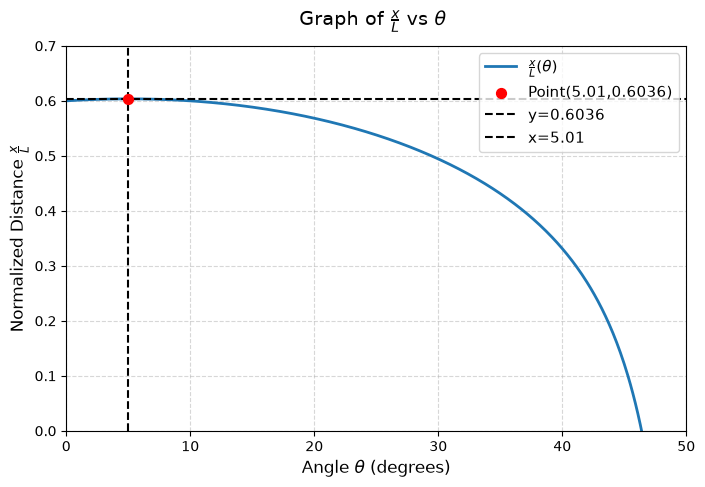

In [494]:
plt.figure(figsize=(8, 5))
plt.plot(theta_deg, ratio, color='tab:blue', linewidth=2, label=r'$\frac{x}{L}(\theta)$')
plt.scatter(5.01, 0.6036, color='red', s=50, zorder=5, label='Point(5.01,0.6036)')
plt.axhline(y=0.6036, color='black', linestyle='--',linewidth=1.5, label='y=0.6036')
plt.axvline(x=5.01, color='black', linestyle='--',linewidth=1.5, label='x=5.01')
plt.title(r'Graph of $\frac{x}{L}$ vs $\theta$ ', fontsize=14, pad=15)
plt.xlabel(r'Angle $\theta$ (degrees)', fontsize=12)
plt.ylabel(r'Normalized Distance $\frac{x}{L}$', fontsize=12)
plt.xlim(0, 50)
plt.ylim(0, 0.7)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=11, loc='upper right')
plt.show()

---

## Phase 3: Impending Slip to the Right

### Equilibrium Configuration
At Phase 3, the system reaches a point of impending slide to the right at a higher angle $\theta_2$. The static friction at support $A$ reaches its limit $f_A = \mu_s N_A$ and acts towards the left.

The free body diagram for phase 3 is as follows:
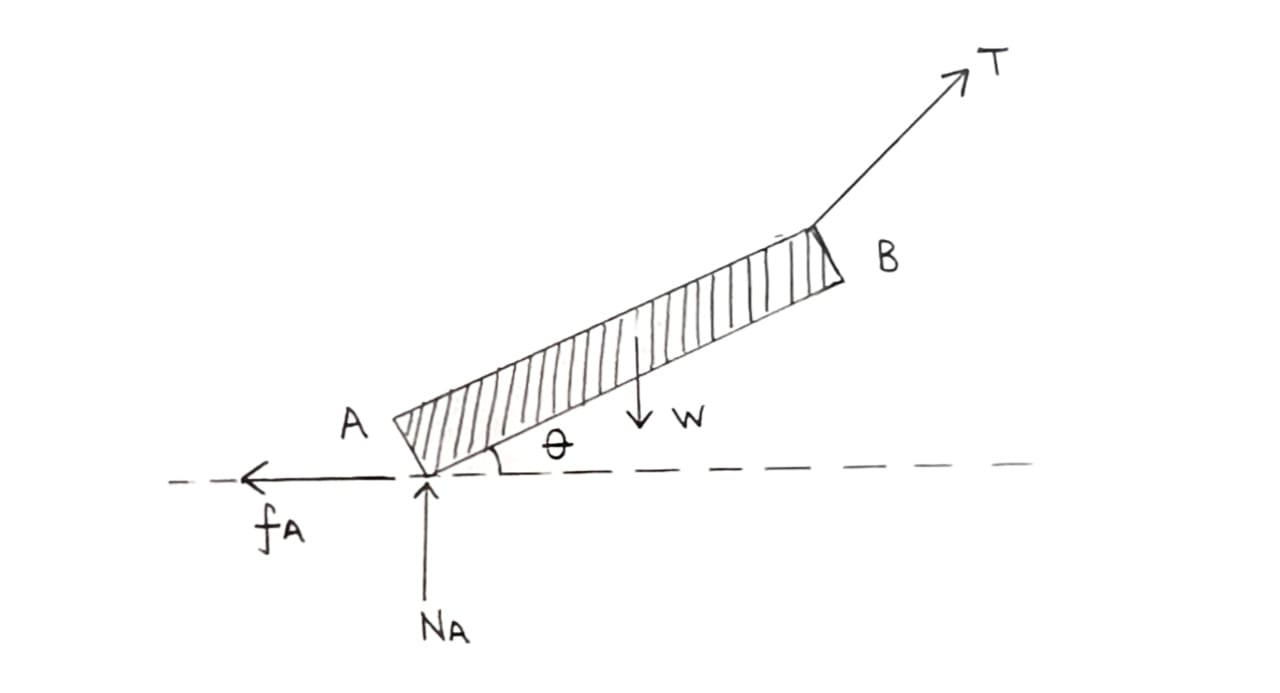
The analytical equation for the position under this condition is:

$$\Sigma F_x = 0$$

* Friction force at A:
  $$f_A = \frac{T}{D}(x - L\cos\theta)$$

* Normal force:
  $$N = W - \frac{T}{D}L(1 - \sin\theta)$$

* Tension-to-distance ratio:
  $$\frac{T}{D} = \frac{W\cos\theta}{2(L\cos\theta - x\sin\theta)}$$

### **Impending Slip Condition**
$$ f_A = \mu_s N \longrightarrow \text{impending slip to right}$$
Substituting the equilibrium equations into this condition yields the final simplified expression for **$x$**:

$$x = \frac{L\cos\theta \, \big(\cos\theta + \mu_s(1 + \sin\theta)\big)}{\cos\theta + 2\mu_s\sin\theta}$$

Let us visualise this expression by means of a graph between $x$ and $\theta$.

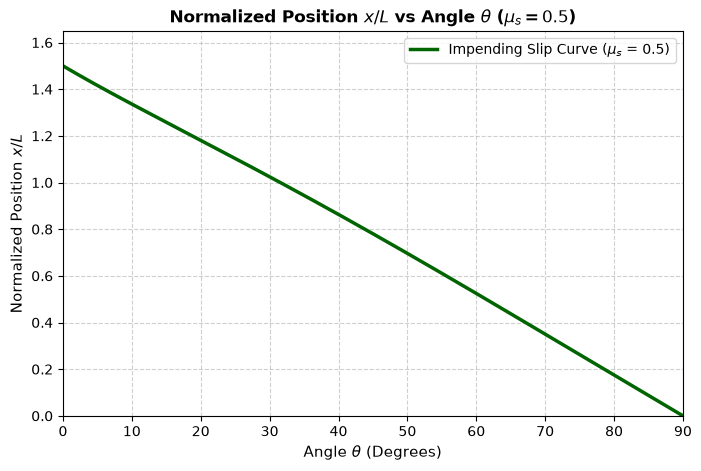

In [495]:
mu_s = 0.5   # Given coefficient of static friction

#Generate theta values (0 to 90 degrees)
theta_deg = np.linspace(0, 90, 1000)
theta_rad = np.radians(theta_deg)

#Compute x/L using the derived formulation in the above markdown 
numerator = np.cos(theta_rad) * (np.cos(theta_rad) + mu_s * (1 + np.sin(theta_rad)))
denominator = np.cos(theta_rad) + 2 * mu_s * np.sin(theta_rad)
x_L = numerator / denominator

#Making the plot
plt.figure(figsize=(8, 5))
plt.plot(theta_deg, x_L, label=f'Impending Slip Curve ($\mu_s$ = {mu_s})', color='darkgreen', lw=2.5)
plt.title(r'Normalized Position $x / L$ vs Angle $\theta$ ($\mu_s = 0.5$)', fontsize=12, fontweight='bold')
plt.xlabel(r'Angle $\theta$ (Degrees)', fontsize=11)
plt.ylabel(r'Normalized Position $x / L$', fontsize=11)
plt.xlim(0, 90)
plt.ylim(0, max(x_L) * 1.1)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='best')

#Displaying graph 
plt.show() 


To find the angle $\theta_2$, set $$x_0 = x_m = 0.6036L$$

Here, $\theta_2 > \theta_1$

Then evaluate the expression and get the value of $\theta_2$.
According to the code below, value of $$\theta_2 = 55.42^\circ$$

In [496]:
# The value of mu_s and the ratio x/L are already declared while making the plot.
# Method of difference of values or bisection is used here. All variables outside any method are global variables.
known_ratio = 0.6036
# Defining function to find difference in values 
def get_diff(theta_deg1):
    theta_rad1 = np.radians(theta_deg1)
    numerator1 = np.cos(theta_rad1) * (np.cos(theta_rad1) + mu_s * (1 + np.sin(theta_rad1)))
    denominator1 = np.cos(theta_rad1) + 2 * mu_s * np.sin(theta_rad1)
    ratio1 = numerator1 / denominator1
    return ratio1 - known_ratio
# Define the boundaries 
low = 0.0
high = 90.0
tolerance = 1e-6
# Bisection loop
for i in range (100):
    mid = (low + high)/2
    diff_mid = get_diff(mid)
    diff_low = get_diff(low)
    check_val = diff_mid if diff_mid>=0 else -diff_mid
    if check_val < tolerance:
        break
    if (diff_mid>0 and diff_low>0) or (diff_mid<0 and diff_low<0):
        low = mid
    else:
        high = mid
# Displaying final value
print(f"Optimal Angle (theta_2): {mid:.4f} degrees")

Optimal Angle (theta_2): 55.4200 degrees


Now, here is a complete version of the plot with the angle included. (Copy pasting the same plotting code, with an additional red dot to go, and lines intersecting at the point)

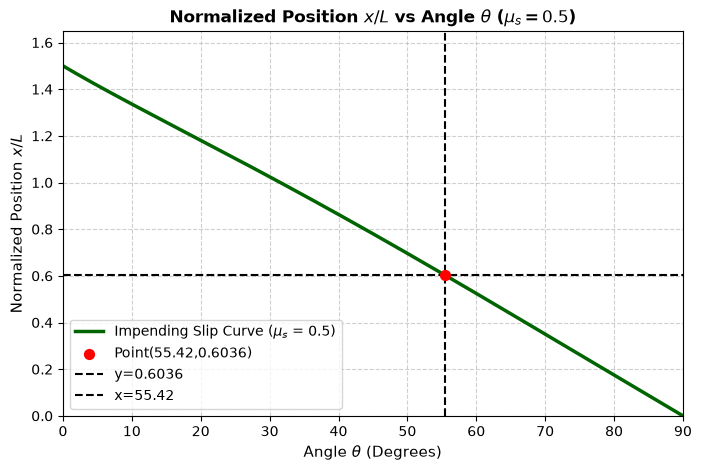

In [497]:
plt.figure(figsize=(8, 5))
plt.plot(theta_deg, x_L, label=f'Impending Slip Curve ($\mu_s$ = {mu_s})', color='darkgreen', lw=2.5)
plt.scatter(55.42,0.6036, color='red', s=50, zorder=5, label='Point(55.42,0.6036)')
plt.axhline(y=0.6036, color='black', linestyle='--',linewidth=1.5, label='y=0.6036')
plt.axvline(x=55.42, color='black', linestyle='--',linewidth=1.5, label='x=55.42')
plt.title(r'Normalized Position $x / L$ vs Angle $\theta$ ($\mu_s = 0.5$)', fontsize=12, fontweight='bold')
plt.xlabel(r'Angle $\theta$ (Degrees)', fontsize=11)
plt.ylabel(r'Normalized Position $x / L$', fontsize=11)
plt.xlim(0, 90)
plt.ylim(0, max(x_L) * 1.1)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='best')
plt.show() 

Now, all the 3 phases are analysed and the values for the edge cases have been found out.
The tabulation is done.

|Parameter|Value|Description|
|:---|:---:|:---|
|$x_0$|$$0.6 L$$|Distance that end A moved before end B got lifted up|
|$x_m$|$$0.6036 L$$|Maximum leftward displacement of end A of the beam|
|$\theta_1$|$5.01^\circ$|Angle of inclination of beam wrt ground when end A covers $x_m$|
|$\theta_2$|$55.42^\circ$|Angle of inclination of beam wrt ground when end A is impending to slip rightward|

### Program Implementation

Now, for the specific things: We have already found out the values of $x_0$, $x_m$, $\theta_1$ and $\theta_2$ as asked in parts (a) and (b) of the question. In a way, we have already completed writing down the codes of both the parts.
Now, as mentioned in part (a), let us find the values of x for a random range of values of theta. (taking care not to reach the asymptotic limits)

Note: Normalized Distance refers to $\frac{x}{L}$.

Note: $\mu_k$ and  $\mu_s$ are global variables which have already been declared in earlier parts of the program.

In [498]:
#Generate a random set of values
import random as rd
#Function to calculate the normalized distance
def calculate_rt1 (angle_deg1):
    angle_rad1 = np.radians(angle_deg1)
    num1 = np.cos(angle_rad1) * (np.cos(angle_rad1) - mu_k * (1 + np.sin(angle_rad1)))
    den1 = np.cos(angle_rad1) - 2 * mu_k * np.sin(angle_rad1)
    if den1 == 0:
        return ("Denominator tends to zero")
    else:
        return num1/den1
array_deg = np.linspace(0,5.01,50)
#Displaying data for a random set of angles
for i in range (5):
    input_val = rd.choice(array_deg)
    output_val = calculate_rt1(input_val)
    print(f"Angle: {input_val} \t Normalized Distance: {output_val:.4f}")
print("For angles between 5.01 and 55.42 (in degrees), normalized distance is 0.6036 as once x_m is reached, end B purely rotates about A.")


Angle: 1.4314285714285713 	 Normalized Distance: 0.6017
Angle: 2.2493877551020405 	 Normalized Distance: 0.6025
Angle: 3.5785714285714283 	 Normalized Distance: 0.6033
Angle: 3.4763265306122446 	 Normalized Distance: 0.6032
Angle: 2.658367346938775 	 Normalized Distance: 0.6028
For angles between 5.01 and 55.42 (in degrees), normalized distance is 0.6036 as once x_m is reached, end B purely rotates about A.


Let us move on to part (b), but the value of $x_m$ has already been calculated for the given condition, all that remains now is a set of random values. This is not related to ny other part of the program, rather it persists on its own as the question just asks what the value of $x$ would be for a variety of values of $\theta$.

In [499]:
#Function to calculate the normalized distance
def  calculate_rt2 (angle_deg2):
    angle_rad2 = np.radians(angle_deg2)
    num2 = np.cos(angle_rad2) * (np.cos(angle_rad2) + mu_s * (1 + np.sin(angle_rad2)))
    den2 = np.cos(angle_rad2) + 2 * mu_s * np.sin(angle_rad2)
    return num2/den2
array1_deg = np.linspace(0,90,500)
#Displaying data for a random set of angles
for i in range (10):
    input_val = rd.choice(array1_deg)
    output_val = calculate_rt2(input_val)
    print(f"Angle: {input_val} \t Normalized Distance: {output_val:.4f}")

Angle: 60.78156312625251 	 Normalized Distance: 0.5110
Angle: 62.2244488977956 	 Normalized Distance: 0.4859
Angle: 50.50100200400802 	 Normalized Distance: 0.6877
Angle: 33.90781563126253 	 Normalized Distance: 0.9621
Angle: 53.386773547094194 	 Normalized Distance: 0.6385
Angle: 33.90781563126253 	 Normalized Distance: 0.9621
Angle: 54.649298597194395 	 Normalized Distance: 0.6168
Angle: 71.96392785571143 	 Normalized Distance: 0.3157
Angle: 74.30861723446894 	 Normalized Distance: 0.2745
Angle: 54.829659318637276 	 Normalized Distance: 0.6137


## Bibliography And Credits:

* **Question**: Problem 8.C8 of Vector Mechanics for Engineers (Tenth Edition) by Beer, Johnston, Mazurek and Cornwell
* **Reference 1**: Class Notes of BEM
* **Reference 2**: Youtube Shorts and Videos that helped in plotting the graphs and creating the tables
* **Free body diagrams**: Hand drawn, scanned and uploaded
* **AI Usage**: Used to correct logical errors that cropped up while running the code, a certain amount was used to learn the various formats in the markdown text area, only Gemini was used.
* Finally, using the random sets of data was the programmer's idea, as having values set in stone are boring and take the fun out of doing the computational part.

PS: Here are the scanned images of the pen and paper work for validation and cross verification.

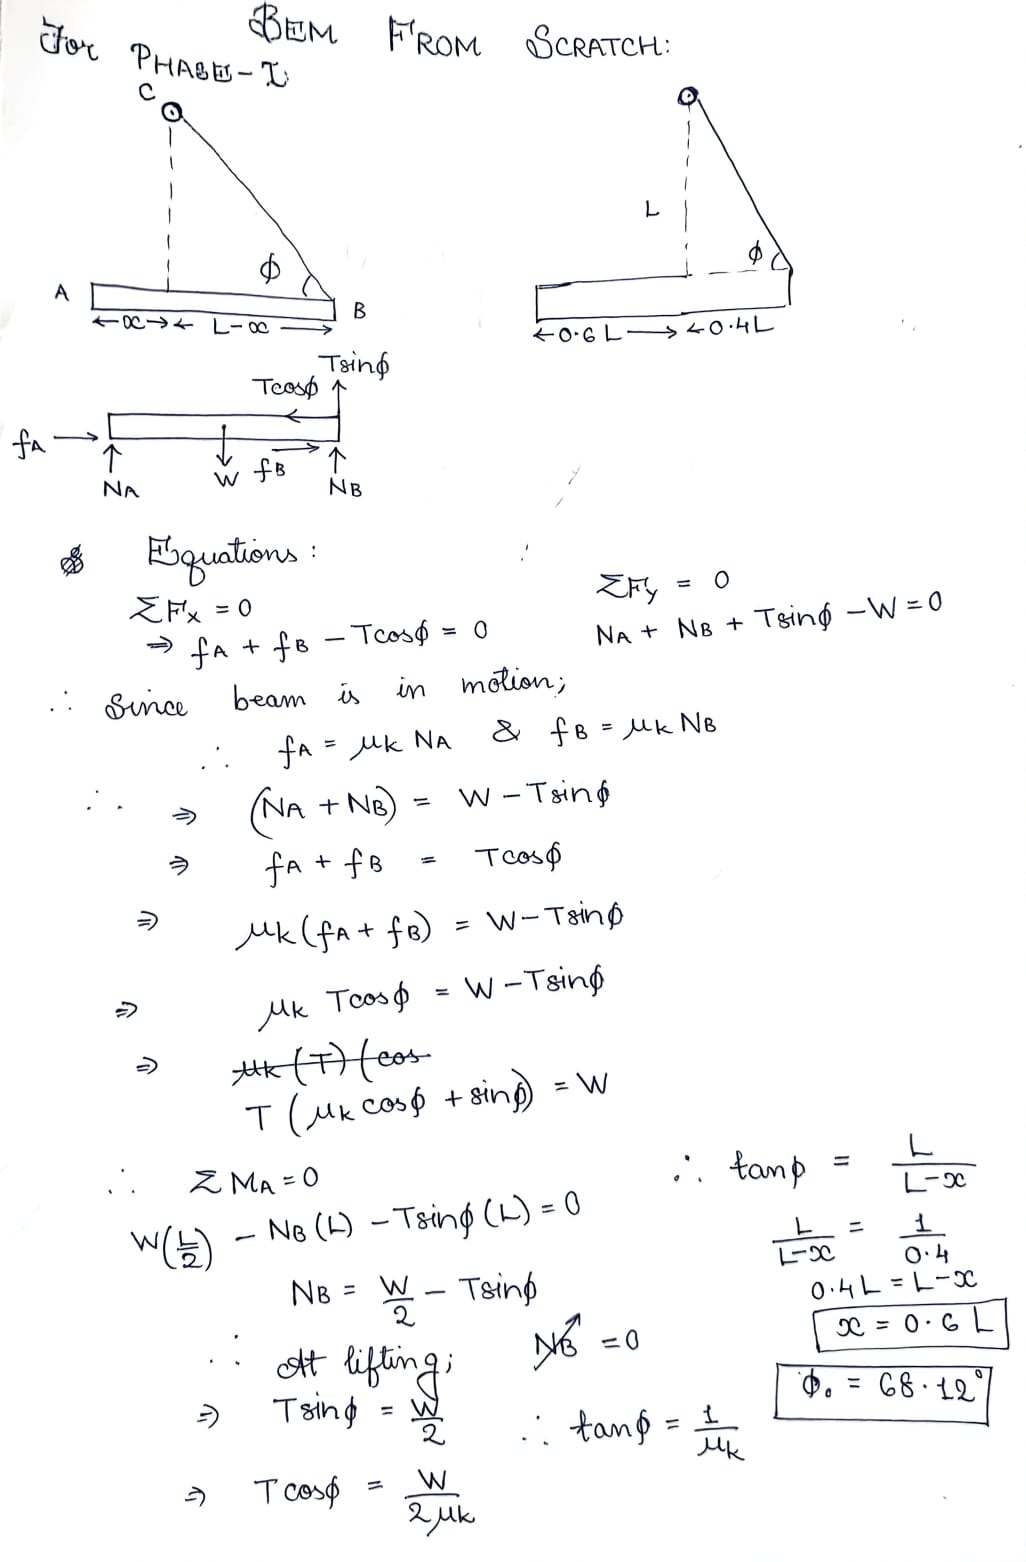
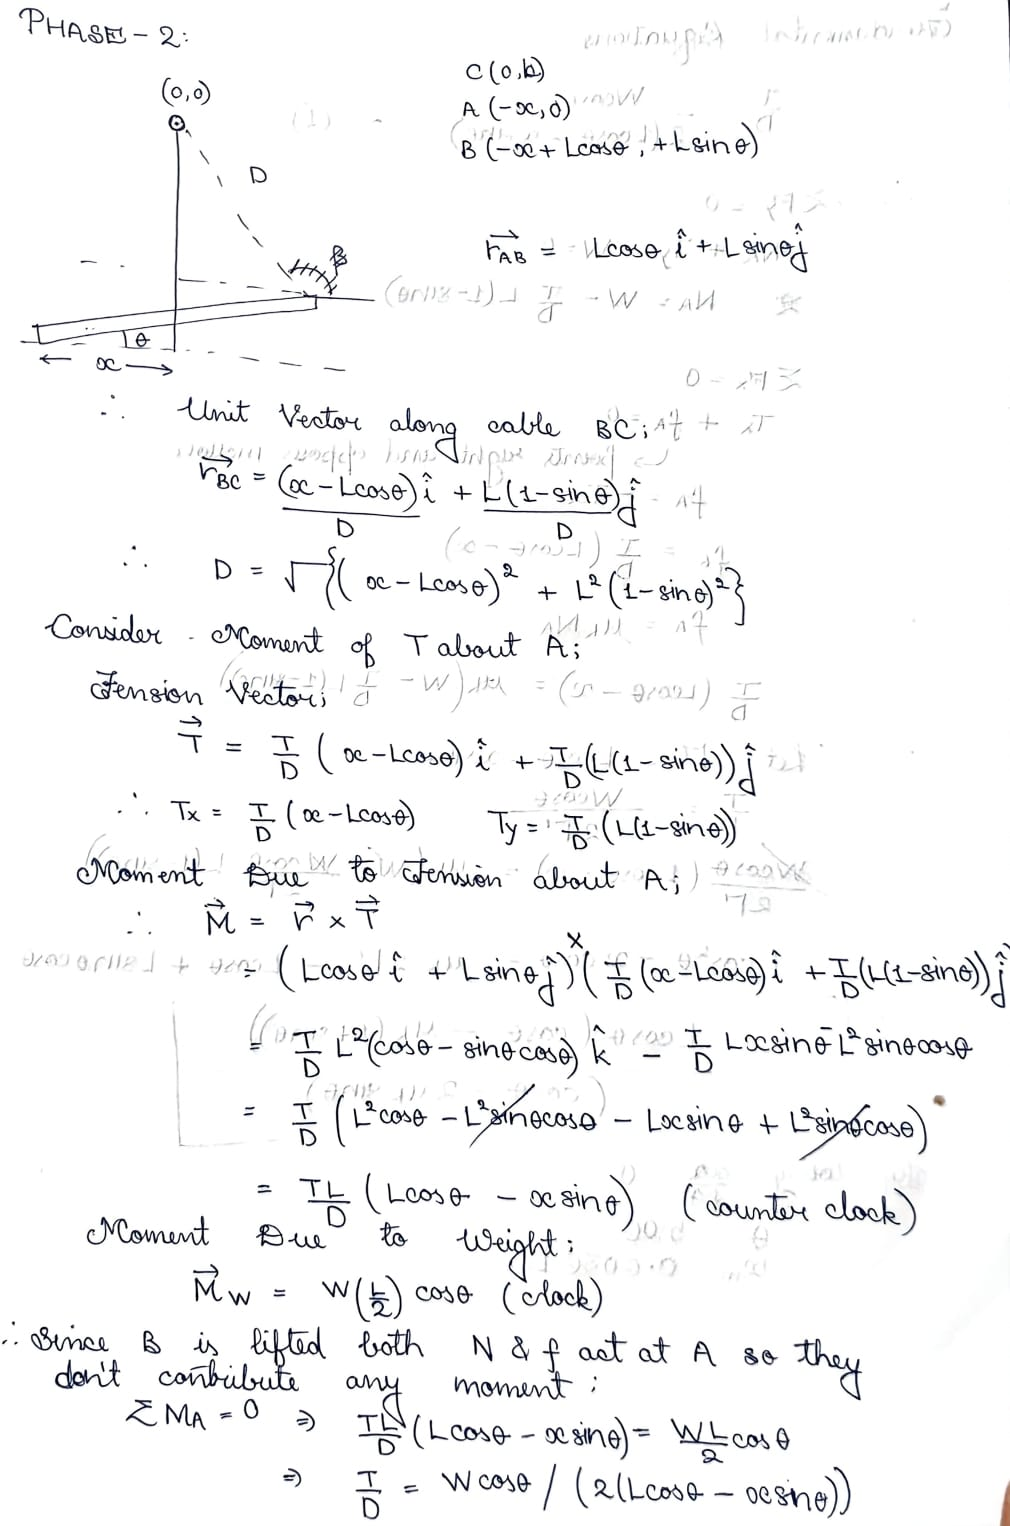
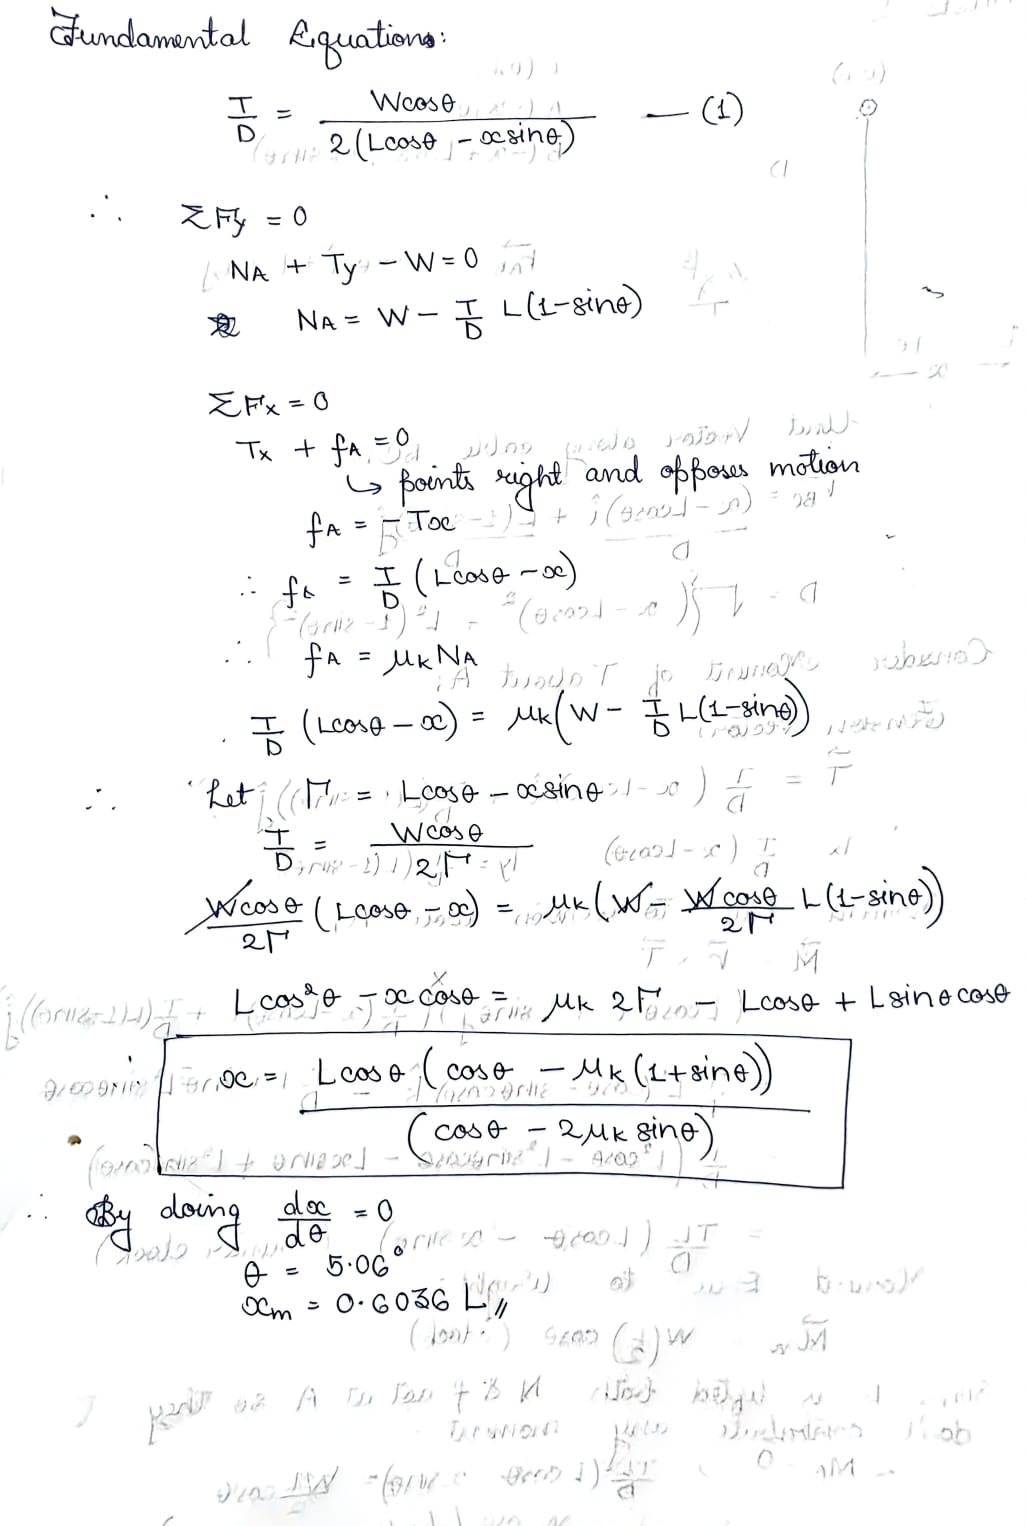
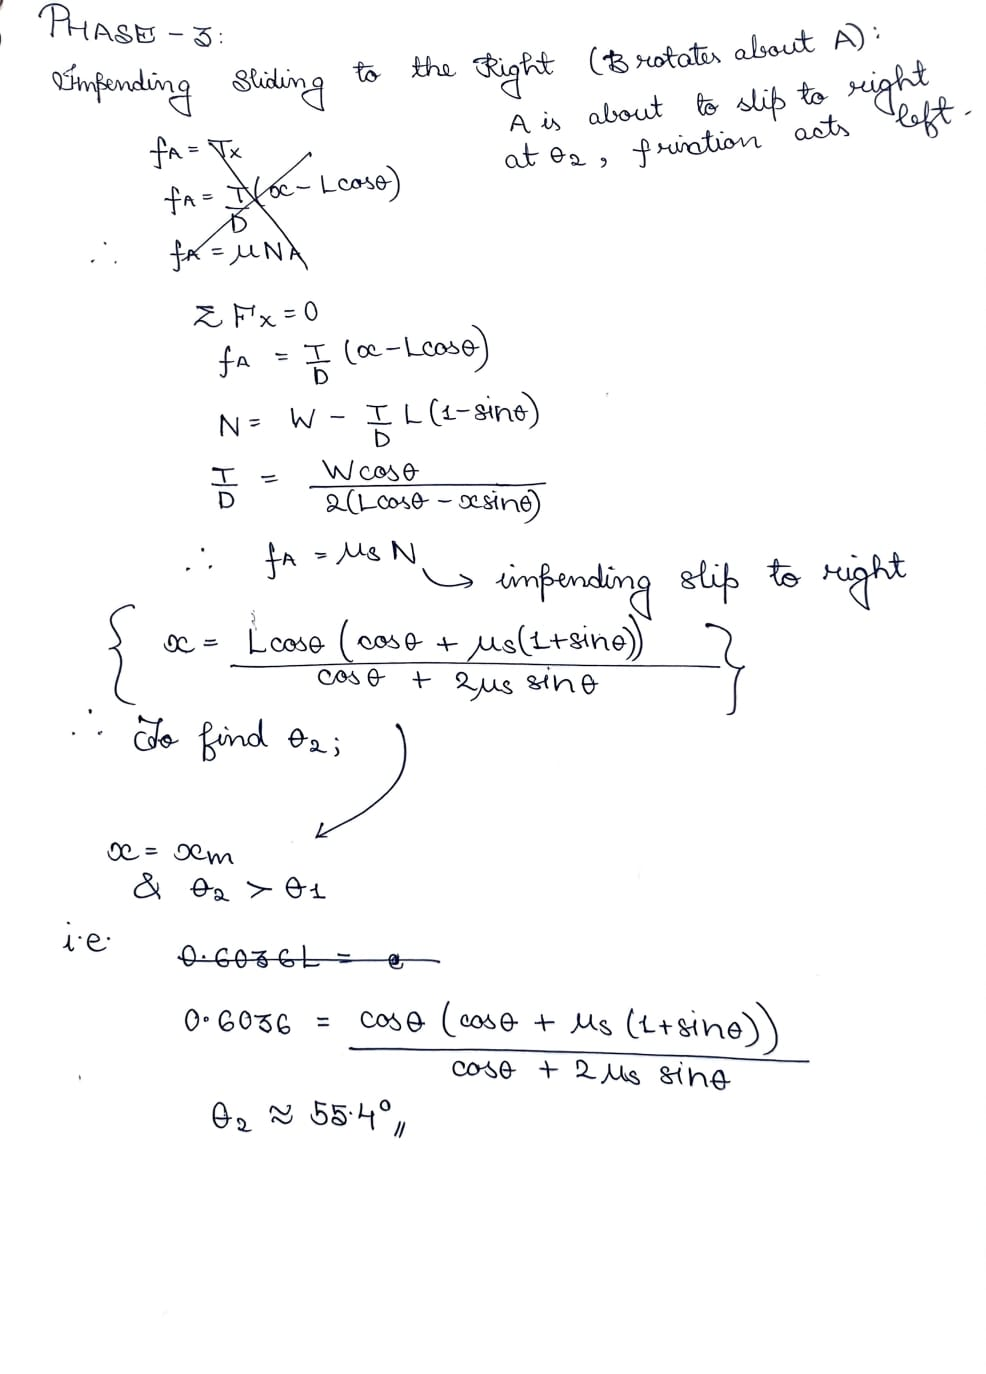

## Discussion: 
Starting off with basics, this problem is specifically curated to trigger the visualising ability of an individual. Though it took some time, we could successfully understand the hidden logic behind this problem by breaking up the total system motion into 3 different phases as discussed above. Once the visualisation was done, the next key thing was to determine the specified normalised distances at the end of phases 1 and 2. This was carefully done by analysing the 3 fundamental equations of equilibrium in static mechanics. Further these results were cross verified by plotting the required graphs. A hand written solution to this question has also been attached for reference. Conclusively, the program as mentioned in parts (a) and (b) of the question was implemented succesfully.

**THANK YOU**